# A. Model considering only the main sequence (only the disease we are interested in studying)

### 1. Adj matrix importing

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

adj_GGM_df = pd.read_csv("results_GGM/GGM_adj_main_par_full.csv", index_col=0)

In [2]:
adj_GGM_df.head()

,Neoplasm Metastasis,"History, Siblings, Stroke",Pericarditis,"Employment, no","History, Mother, Heart Diseases","Kidney Diseases, Chronic, Stage 5","Socioeconomic Factors, middle","Socioeconomic Factors, high","Pacemaker, Artificial",Postoperative Complications,...,"Educational Status, high","Ethnic, Other",Myocarditis,"Pulmonary Disease, Obstructive","History, Mother, Stroke",Sepsis,"Cardiomyopathy, Drug Induced",Pre diabetic State,Purpura,"Leukopenia, low"
Neoplasm Metastasis,0.000000e+00,-2.849173e-07,0.000829,-0.000300,-0.000019,0.000000,0.000020,0.000000e+00,-0.001097,-2.371417e-04,...,1.710041e-04,0.0,-4.192494e-05,0.000000,-0.000058,-7.126469e-04,0.000234,-0.000572,-5.271261e-04,0.000000e+00
"History, Siblings, Stroke",-2.849173e-07,0.000000e+00,0.000000,0.000000,0.000002,0.000000,-0.000029,0.000000e+00,0.000038,0.000000e+00,...,0.000000e+00,0.0,2.929901e-10,0.000000,-0.000008,0.000000e+00,0.000000,0.000000,0.000000e+00,3.057474e-05
Pericarditis,8.291907e-04,0.000000e+00,0.000000,-0.001047,0.000000,0.001030,-0.000416,0.000000e+00,-0.000732,-5.080609e-03,...,0.000000e+00,0.0,-1.000556e-04,0.000103,0.000000,0.000000e+00,0.000000,0.001122,-9.370557e-04,0.000000e+00
"Employment, no",-3.003293e-04,0.000000e+00,-0.001047,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000e+00,...,0.000000e+00,0.0,2.225799e-03,0.000006,0.000000,0.000000e+00,0.000000,0.000047,0.000000e+00,0.000000e+00
"History, Mother, Heart Diseases",-1.927462e-05,1.617979e-06,0.000000,0.000000,0.000000,-0.000003,0.000000,1.645651e-07,0.000000,4.795524e-08,...,1.013420e-08,0.0,0.000000e+00,0.000000,-0.000012,-1.899244e-07,0.000000,0.000026,5.934864e-08,-1.541820e-07


### 2. Network construction and visualization

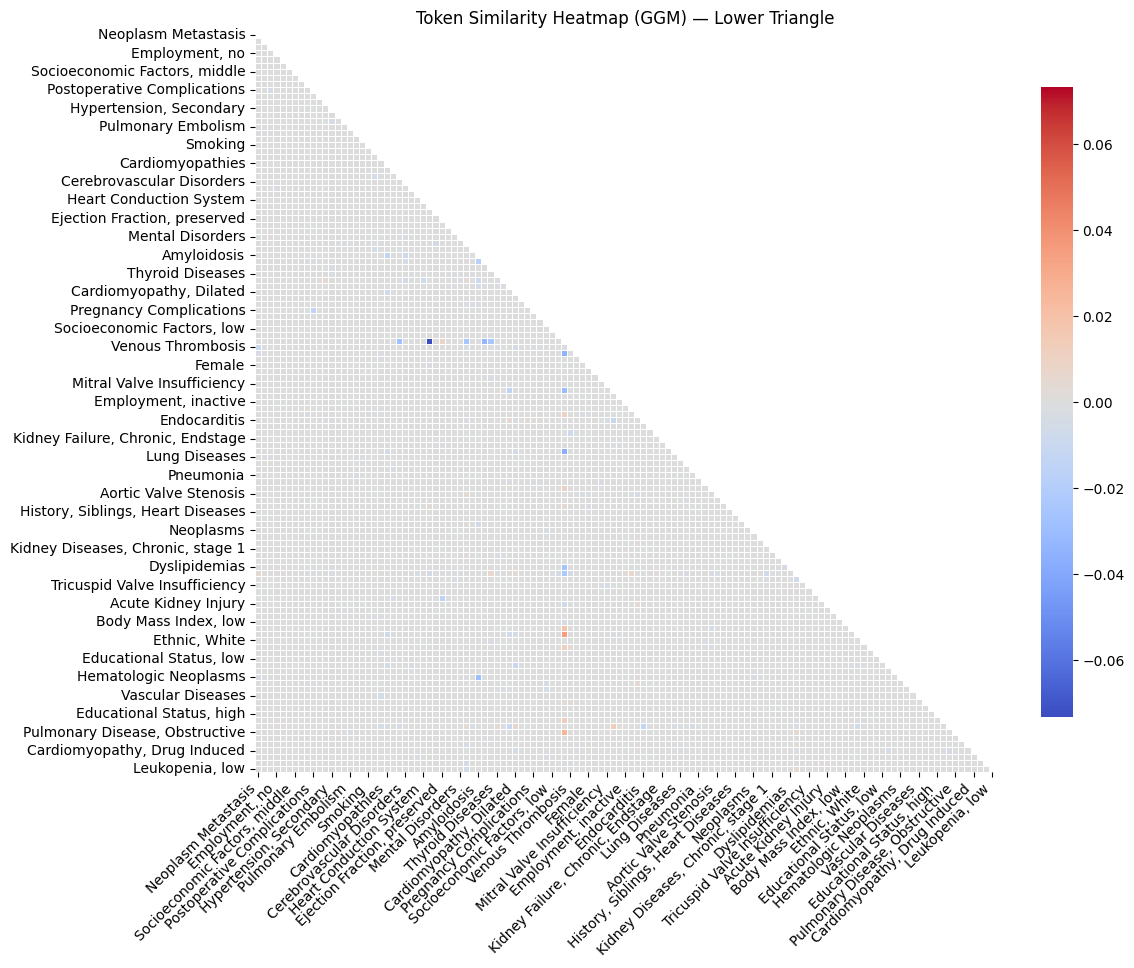

In [3]:
# Mask: hide upper triangle + diagonal -> show only lower triangle (excluding diagonal)
mask = np.triu(np.ones(adj_GGM_df.shape, dtype=bool), k=0)
vmax = np.nanmax(np.abs(adj_GGM_df.values))
vmin = -vmax

plt.figure(figsize=(12, 10))
sns.heatmap(
    adj_GGM_df,
    mask=mask,
    cmap="coolwarm",          
    annot=False,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    center=0,          
    vmin=vmin, vmax=vmax
)

plt.title("Token Similarity Heatmap (GGM) — Lower Triangle")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("disease_GGM_heatmap_main_par_full_weighted.svg", format="svg")
plt.show()

In [4]:
df_main = pd.read_csv('sequence_main_final.csv')
main_d = df_main["disease_name"].unique()
md = sorted(set(main_d) & set(adj_GGM_df.index) & set(adj_GGM_df.columns))
adj_GGM_df_main = adj_GGM_df.loc[md, md]

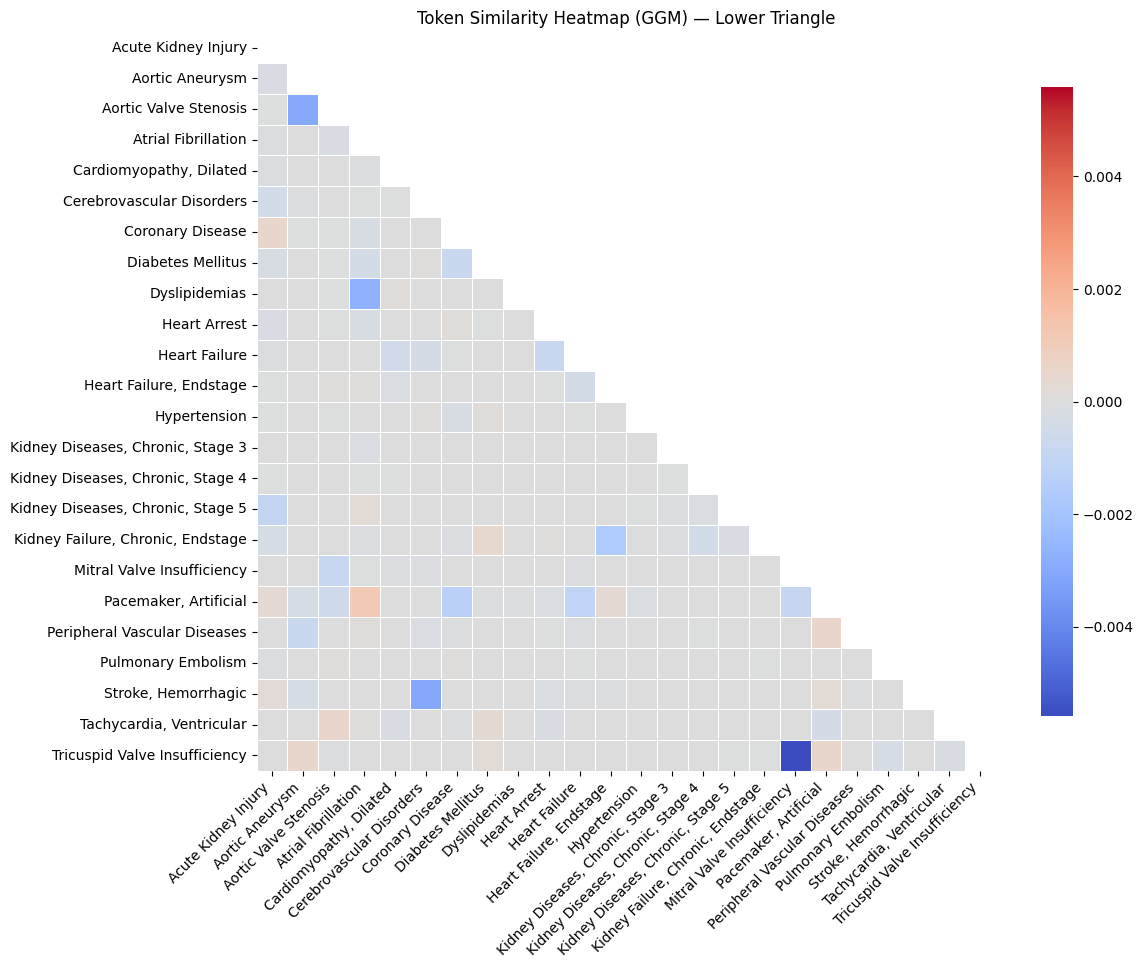

In [5]:
# Mask: hide upper triangle + diagonal -> show only lower triangle (excluding diagonal)
mask = np.triu(np.ones(adj_GGM_df_main.shape, dtype=bool), k=0)
vmax = np.nanmax(np.abs(adj_GGM_df_main.values))
vmin = -vmax

plt.figure(figsize=(12, 10))
sns.heatmap(
    adj_GGM_df_main,
    mask=mask,
    cmap="coolwarm",          
    annot=False,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    center=0,          
    vmin=vmin, vmax=vmax
)

plt.title("Token Similarity Heatmap (GGM) — Lower Triangle")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("disease_GGM_heatmap_main_par_weighted.svg", format="svg")
plt.show()

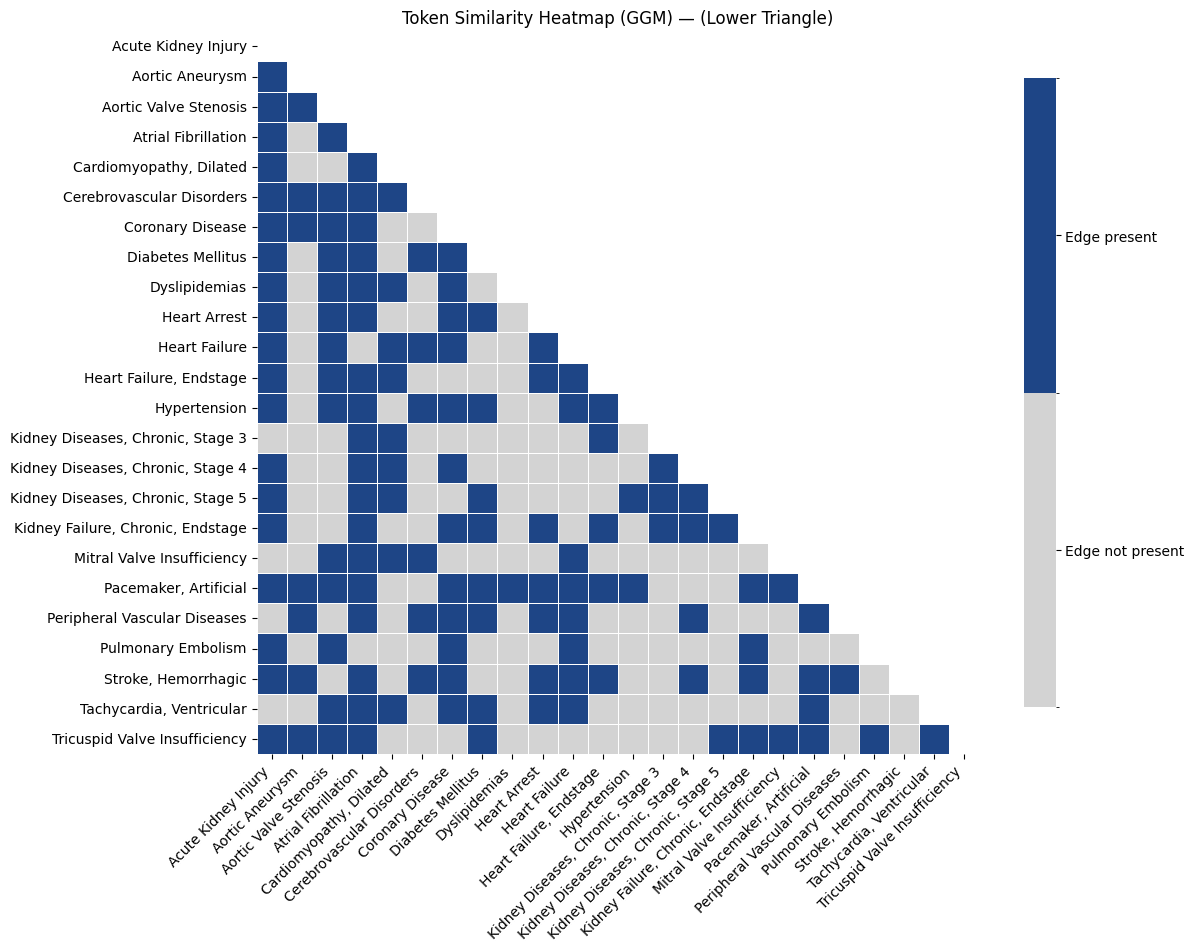

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap, BoundaryNorm

# show only lower triangle (exclude diagonal)
mask = np.triu(np.ones(adj_GGM_df_main.shape, dtype=bool), k=0)

vals = adj_GGM_df_main.to_numpy()

# 0 if exactly zero, 1 otherwise (binary)
sign_mat = np.where(vals == 0, 0, 1)

# discrete colors: 0 -> light gray, 1 -> blue
cmap = ListedColormap(["lightgray", "#1E4586"])
norm = BoundaryNorm([-0.5, 0.5, 1.5], cmap.N)

plt.figure(figsize=(12, 10))
ax = sns.heatmap(
    sign_mat,
    mask=mask,
    cmap=cmap,
    norm=norm,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "ticks": [0, 1]}
)

# restore labels (since sign_mat is a numpy array)
ax.set_xticks(np.arange(adj_GGM_df_main.shape[1]) + 0.5)
ax.set_yticks(np.arange(adj_GGM_df_main.shape[0]) + 0.5)
ax.set_xticklabels(adj_GGM_df_main.columns, rotation=45, ha="right")
ax.set_yticklabels(adj_GGM_df_main.index, rotation=0)

cbar = ax.collections[0].colorbar
cbar.set_ticklabels(["Edge not present", "Edge present"])

plt.title("Token Similarity Heatmap (GGM) — (Lower Triangle)")
plt.tight_layout()
plt.savefig("disease_GGM_heatmap_main_par_binary.svg", format="svg")
plt.show()


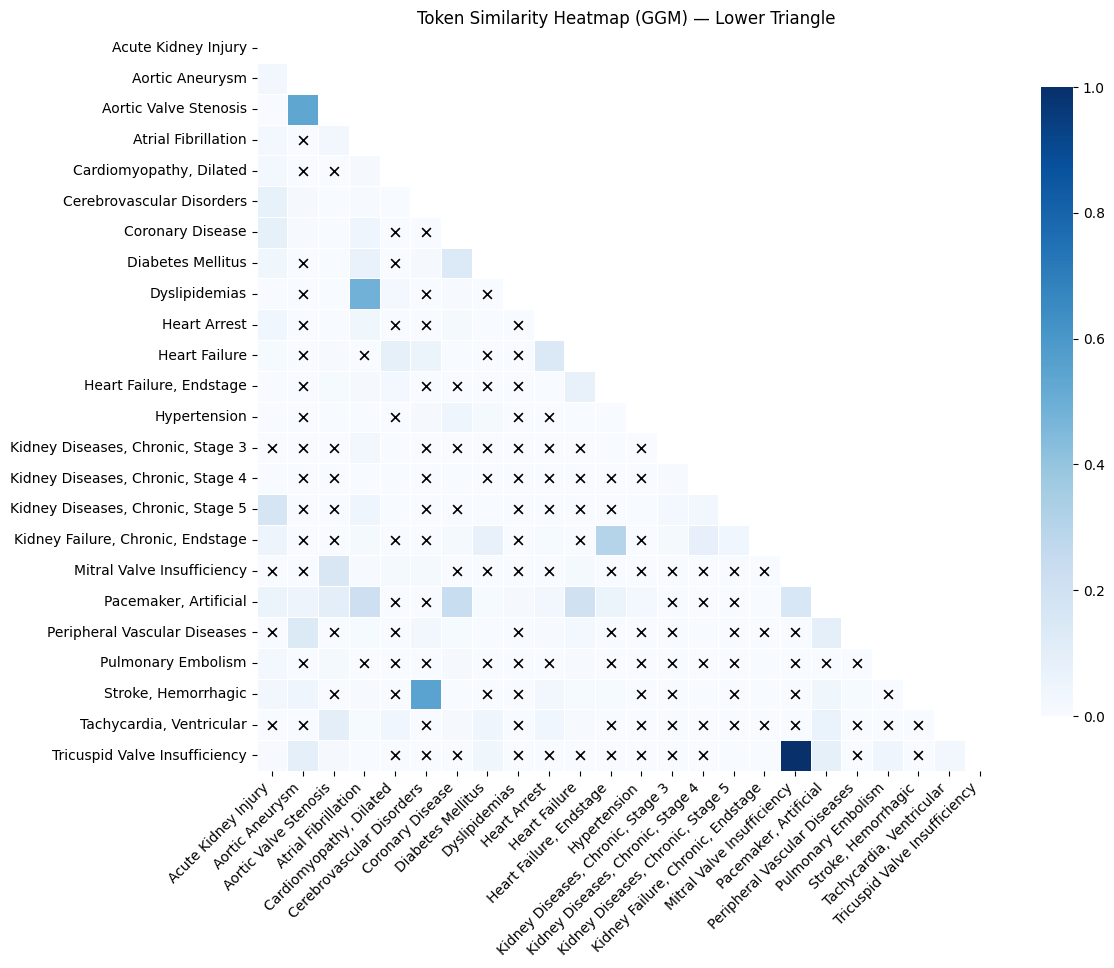

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# abs + normalize to [0,1]
adj_GGM_df_main_abs = adj_GGM_df_main.abs()
max_val = np.nanmax(adj_GGM_df_main_abs.to_numpy())
adj_GGM_df_main_norm = adj_GGM_df_main_abs / max_val

# show only lower triangle (exclude diagonal)
mask = np.triu(np.ones(adj_GGM_df_main_norm.shape, dtype=bool), k=0)

plt.figure(figsize=(12, 10))
ax = sns.heatmap(
    adj_GGM_df_main_norm,
    mask=mask,
    cmap="Blues",
    annot=False,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    vmin=0, vmax=1
)

# --- add X on exactly-zero edges (in the displayed lower triangle) ---
zero_mask = (adj_GGM_df_main.to_numpy() == 0)              # where original is exactly 0
lower_mask = np.tril(np.ones(zero_mask.shape, bool), k=-1) # only below diagonal
mark = zero_mask & lower_mask

ys, xs = np.where(mark)  # row, col indices
ax.scatter(xs + 0.5, ys + 0.5, marker="x", s=40, linewidths=1.2, color="black")
# -------------------------------------------------------------------

plt.title("Token Similarity Heatmap (GGM) — Lower Triangle")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("disease_GGM_heatmap_main_par_weighted_normalized.svg", format="svg")
plt.show()


In [26]:
import networkx as nx
def weighted_graph_construction(correlation_df, threshold):
    """
    Construct the weighted graph based on a correlation matrix.
 
    Parameters:
    - correlation_matrix: numpy array, input correlation matrix
    - threshold: float, correlation threshold for creating edges in the graph
 
    Returns:
    - G: graph, output weighted graph
    """
    # Create a graph from the correlation matrix with weights above the threshold
    correlation_matrix = np.absolute(np.array(correlation_df))
    G = nx.DiGraph()
    num_nodes = correlation_matrix.shape[0]
    prot_names = correlation_df.columns
    G.add_nodes_from(prot_names)
 
    for i in range(num_nodes):
        for j in range(i + 1, num_nodes):
            if np.abs(correlation_matrix[i, j]) > threshold:
                G.add_edge(prot_names[i], prot_names[j], weight=correlation_matrix[i, j])
    print(f'Proportion of #edges: {len(G.edges)/num_nodes**2}')
    G = G.to_undirected()
    return G
 
import matplotlib.pyplot as plt
import networkx as nx
import matplotlib.cm as cm
import matplotlib.colors as mcolors

def plot_weighted_graph_colored(G, cmap_name="coolwarm"):
    """
    Plot a weighted graph with edge colors and transparency based on weight.
    Higher weights = more intense color + less transparency.

    Parameters:
    - G: NetworkX graph with 'weight' attributes on edges
    - cmap_name: Matplotlib colormap name
    """
    plt.figure(figsize=(16, 12))
    ax = plt.gca()
    pos = nx.circular_layout(G)

    # Extract edge weights
    weights = [G[u][v]['weight'] for u, v in G.edges()]
    min_w, max_w = min(weights), max(weights)

    # Normalize weights
    norm = mcolors.Normalize(vmin=min_w, vmax=max_w)
    cmap = plt.colormaps[cmap_name]

    # Map weight to RGBA (color + alpha)
    edge_colors = []
    for w in weights:
        base_color = cmap(norm(w))
        alpha = 0.1 + 0.9 * norm(w)  # scale alpha from 0.1 (faint) to 1.0 (solid)
        edge_colors.append((base_color[0], base_color[1], base_color[2], alpha))

    # Draw graph
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=600, node_color='lightgray')
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=10, font_color='black')
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=edge_colors, width=2)

    # Add colorbar
    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, shrink=0.7)
    cbar.set_label("Similarity", fontsize=12)

    plt.title("Graph Colored by Edge Similarity", fontsize=14)
    plt.axis("off")
    plt.tight_layout()
    plt.savefig("graph_GGM_plot_main_weighted_normlized.svg", format="svg")
    
    plt.show()


def plot_weighted_graph_colored(G, cmap_name="coolwarm", layout="circular"):
    """
    Plot a weighted graph with edge colors and transparency based on weight.
    Higher weights = more intense color + less transparency.
    Handles the case where all weights are equal (e.g., binary graphs with all 1s).
    """
    plt.figure(figsize=(16, 12))
    ax = plt.gca()

    # layout
    if layout == "spring":
        pos = nx.spring_layout(G, seed=1)
    elif layout == "kamada_kawai":
        pos = nx.kamada_kawai_layout(G)
    else:
        pos = nx.circular_layout(G)

    if G.number_of_edges() == 0:
        nx.draw_networkx_nodes(G, pos, ax=ax, node_size=600, node_color="lightgray")
        nx.draw_networkx_labels(G, pos, ax=ax, font_size=10, font_color="black")
        plt.title("Graph (no edges after threshold)", fontsize=14)
        plt.axis("off")
        plt.tight_layout()
        plt.savefig("graph_GGM_plot_main_binary.svg", format="svg")
        plt.show()
        return

    # Extract edge weights
    weights = [G[u][v].get("weight", 1.0) for u, v in G.edges()]
    min_w, max_w = min(weights), max(weights)

    cmap = plt.colormaps[cmap_name]

    # If all weights are the same, use a fixed normalization range
    # so color + alpha behave nicely.
    if min_w == max_w:
        norm = mcolors.Normalize(vmin=0, vmax=1)
        edge_colors = [(*cmap(1.0)[:3], 1.0) for _ in weights]  # solid max color
    else:
        norm = mcolors.Normalize(vmin=min_w, vmax=max_w)
        edge_colors = []
        for w in weights:
            base_color = cmap(norm(w))
            alpha = 0.1 + 0.9 * norm(w)  # 0.1..1.0
            edge_colors.append((base_color[0], base_color[1], base_color[2], alpha))

    # Draw graph
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=600, node_color="lightgray")
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=10, font_color="black")
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=edge_colors, width=2)

    # Add colorbar
    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, shrink=0.7)
    cbar.set_label("Similarity", fontsize=12)

    plt.title("Graph Colored by Edge Similarity", fontsize=14)
    plt.axis("off")
    plt.tight_layout()
    plt.savefig("graph_GGM_plot_main_binary.svg", format="svg")
    plt.show()


Proportion of #edges: 0.23958333333333334


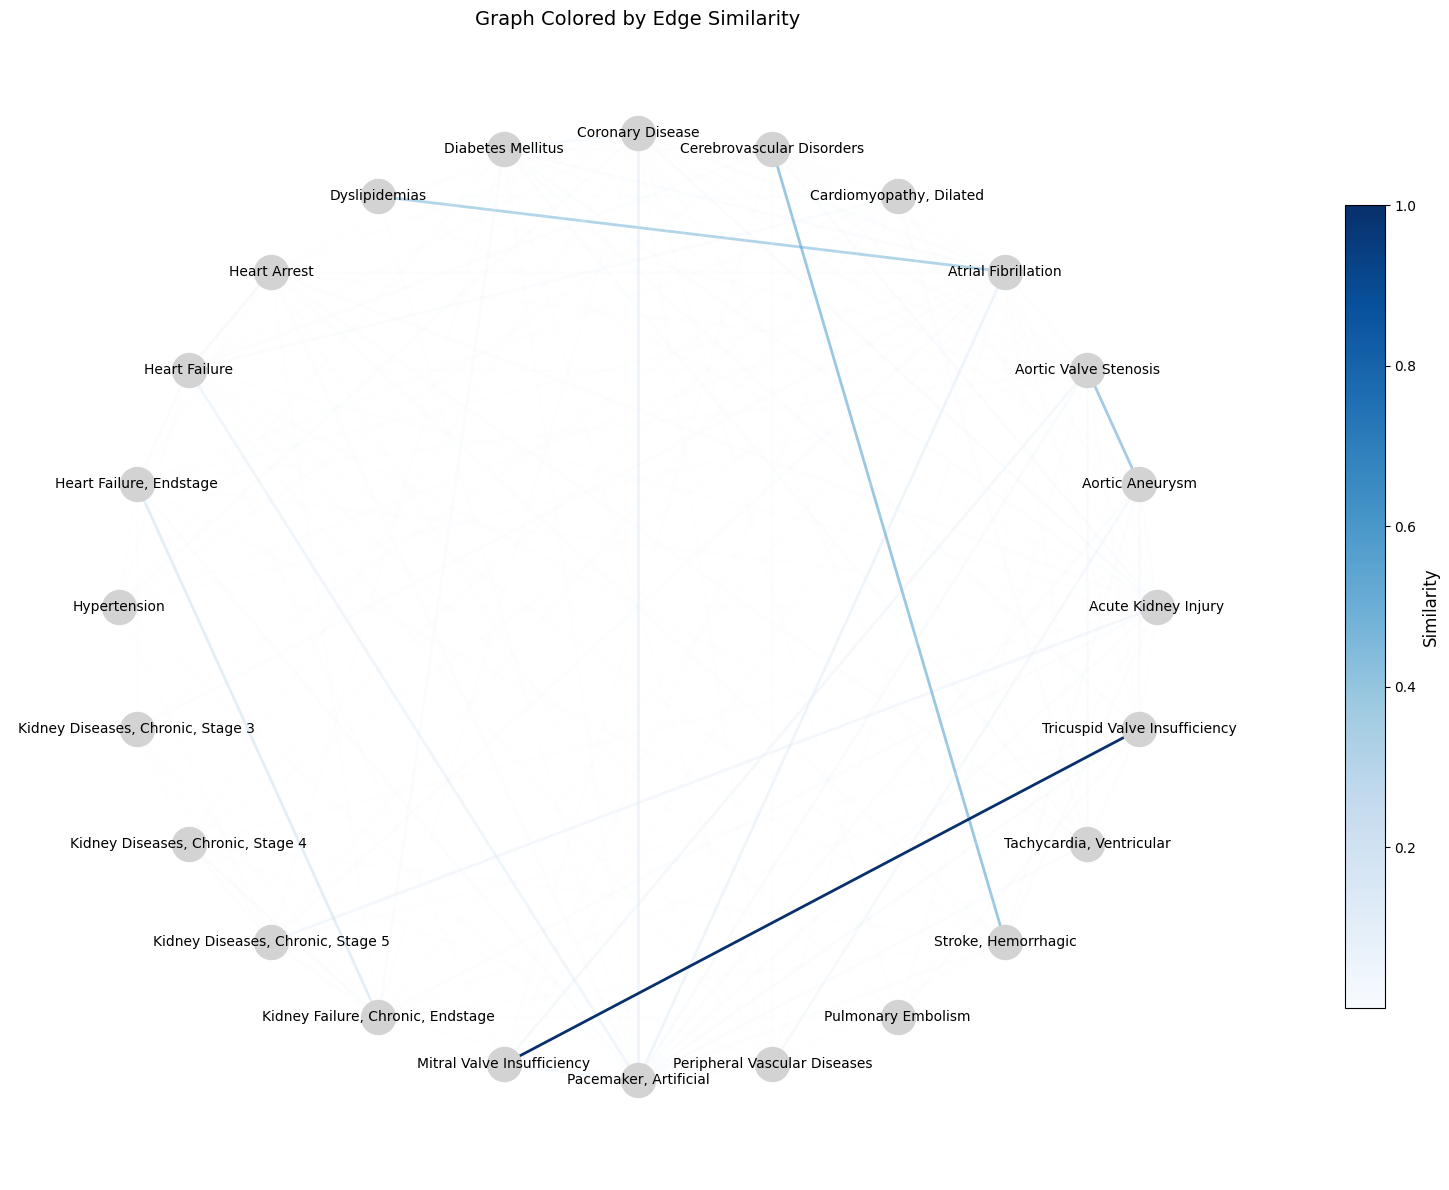

In [27]:
G = weighted_graph_construction(adj_GGM_df_main_norm, threshold=0.0)
plot_weighted_graph_colored(G, cmap_name="Blues")

Proportion of #edges: 0.23958333333333334


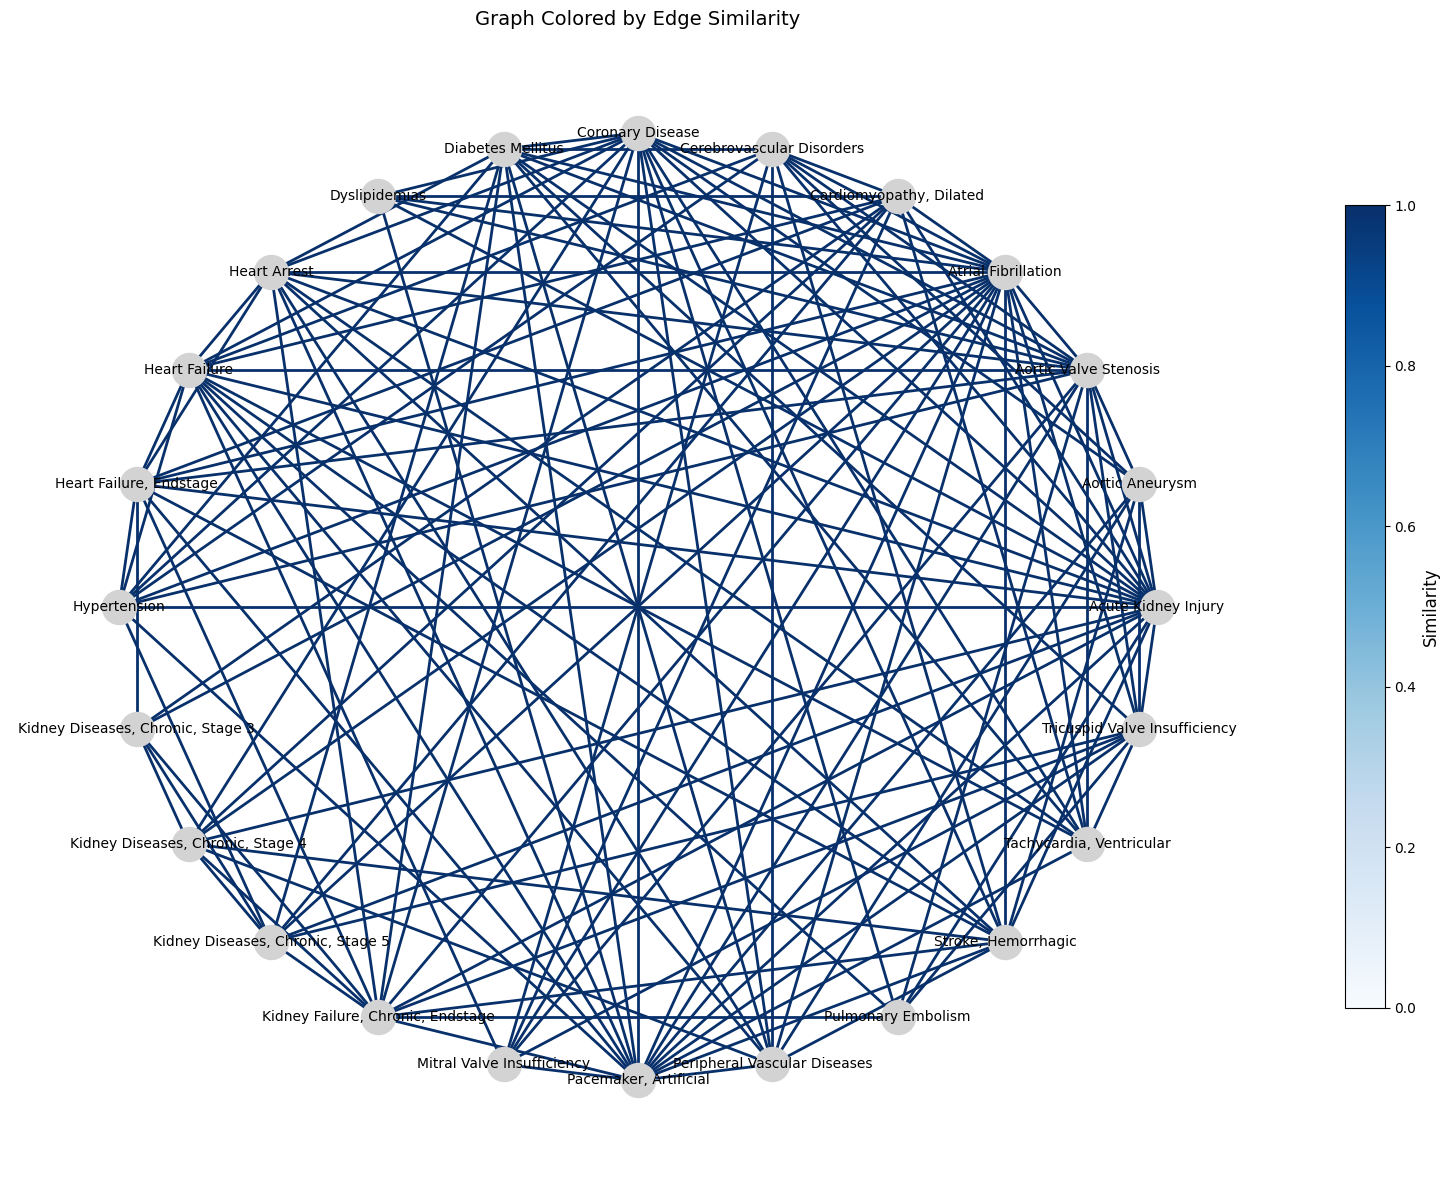

In [25]:
sign_df = pd.DataFrame(
    sign_mat,
    index=adj_GGM_df_main_norm.columns,
    columns=adj_GGM_df_main_norm.columns
)

G = weighted_graph_construction(sign_df, threshold=0.0)
plot_weighted_graph_colored(G, cmap_name="Blues", layout="circular")

### 3. Network analysis visualization

In [44]:
Community_detected = pd.read_csv("Baseline/Node_Community_detection_centrality.csv", index_col=0)
Community_detected.head()

,Node,cfg_community,centrality_degree,betweenness
1,"Kidney Diseases, Chronic, Stage 5",1,9,2.956190
2,"Pacemaker, Artificial",2,17,11.165971
3,Heart Failure,2,14,8.550397
4,Hypertension,1,10,2.029304
5,Pulmonary Embolism,2,6,0.531746


In [45]:
Community_detected["centrality_degree_rank"] = (
    Community_detected["centrality_degree"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# 2) rank betweenness (1 = highest)
Community_detected["centrality_betweenness_rank"] = (
    Community_detected["betweenness"]
    .rank(method="min", ascending=False)
    .astype(int)
)
Community_detected

,Node,cfg_community,centrality_degree,betweenness,centrality_degree_rank,centrality_betweenness_rank
1,"Kidney Diseases, Chronic, Stage 5",1,9,2.956190,17,15
2,"Pacemaker, Artificial",2,17,11.165971,3,3
3,Heart Failure,2,14,8.550397,6,6
4,Hypertension,1,10,2.029304,15,18
5,Pulmonary Embolism,2,6,0.531746,22,22
6,Cerebrovascular Disorders,3,11,4.350574,11,12
7,Diabetes Mellitus,2,13,4.732540,7,10
8,"Stroke, Hemorrhagic",3,12,3.715098,9,13
9,"Cardiomyopathy, Dilated",1,11,8.320415,11,7
10,Heart Arrest,2,12,2.311050,9,17


In [46]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

def plot_graph_by_community(
    G,
    community_df,
    layout="kamada_kawai",
    node_size=650,
    label_offset=0.04,
    edge_color="lightgray",
    edge_width=1.8,
    out="graph_GGM_by_community.svg",
    # NEW:
    separate_communities=True,
    separation_strength=1.8,   # increase to push communities farther apart (e.g., 2.5 or 3.5)
):
    fig, ax = plt.subplots(figsize=(16, 12))

    # --- base layout ---
    if layout == "circular":
        pos = nx.circular_layout(G)
    elif layout == "spring":
        pos = nx.spring_layout(G, seed=1, k=0.9)  # more space than default
    else:  # kamada_kawai
        pos = nx.kamada_kawai_layout(G)

    # --- node -> community ---
    node_to_comm = dict(zip(community_df["Node"], community_df["cfg_community"]))

    # --- optionally push communities apart ---
    if separate_communities:
        # centroids per community (in layout space)
        comm_nodes = {}
        for n in G.nodes():
            c = node_to_comm.get(n, -1)
            comm_nodes.setdefault(c, []).append(n)

        comm_centroid = {}
        for c, nodes in comm_nodes.items():
            pts = np.array([pos[n] for n in nodes])
            comm_centroid[c] = pts.mean(axis=0)

        global_center = np.mean(np.array(list(pos.values())), axis=0)

        # push each community centroid away from global center
        for c, nodes in comm_nodes.items():
            v = comm_centroid[c] - global_center
            norm = np.linalg.norm(v)
            v = v / norm if norm > 0 else np.array([1.0, 0.0])

            # shift all nodes in this community by a vector proportional to strength
            shift = separation_strength * v
            for n in nodes:
                pos[n] = pos[n] + shift

    # --- color nodes by community ---
    comms = sorted({node_to_comm.get(n, -1) for n in G.nodes()})
    cmap = plt.colormaps["tab20"]
    comm_to_color = {c: cmap(i / max(1, (len(comms) - 1))) for i, c in enumerate(comms)}
    node_colors = [comm_to_color[node_to_comm.get(n, -1)] for n in G.nodes()]

    # edges
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=edge_color, width=edge_width, alpha=0.8)

    # nodes
    nx.draw_networkx_nodes(
        G, pos, ax=ax,
        node_color=node_colors,
        node_size=node_size,
        linewidths=0.8,
        edgecolors="white"
    )

    # --- labels (shift outward from global center) ---
    center = np.mean(np.array(list(pos.values())), axis=0)
    pos_labels = {}
    for n, (x, y) in pos.items():
        vv = np.array([x, y]) - center
        nn = np.linalg.norm(vv)
        vv = vv / nn if nn > 0 else np.array([1.0, 0.0])
        pos_labels[n] = (x + label_offset * vv[0], y + label_offset * vv[1])

    nx.draw_networkx_labels(G, pos_labels, ax=ax, font_size=10, font_color="black")

    ax.set_title("Graph Colored by Community", fontsize=14)
    ax.axis("off")
    plt.tight_layout()
    plt.savefig(out, format="svg")
    plt.show()


Proportion of #edges: 0.23958333333333334


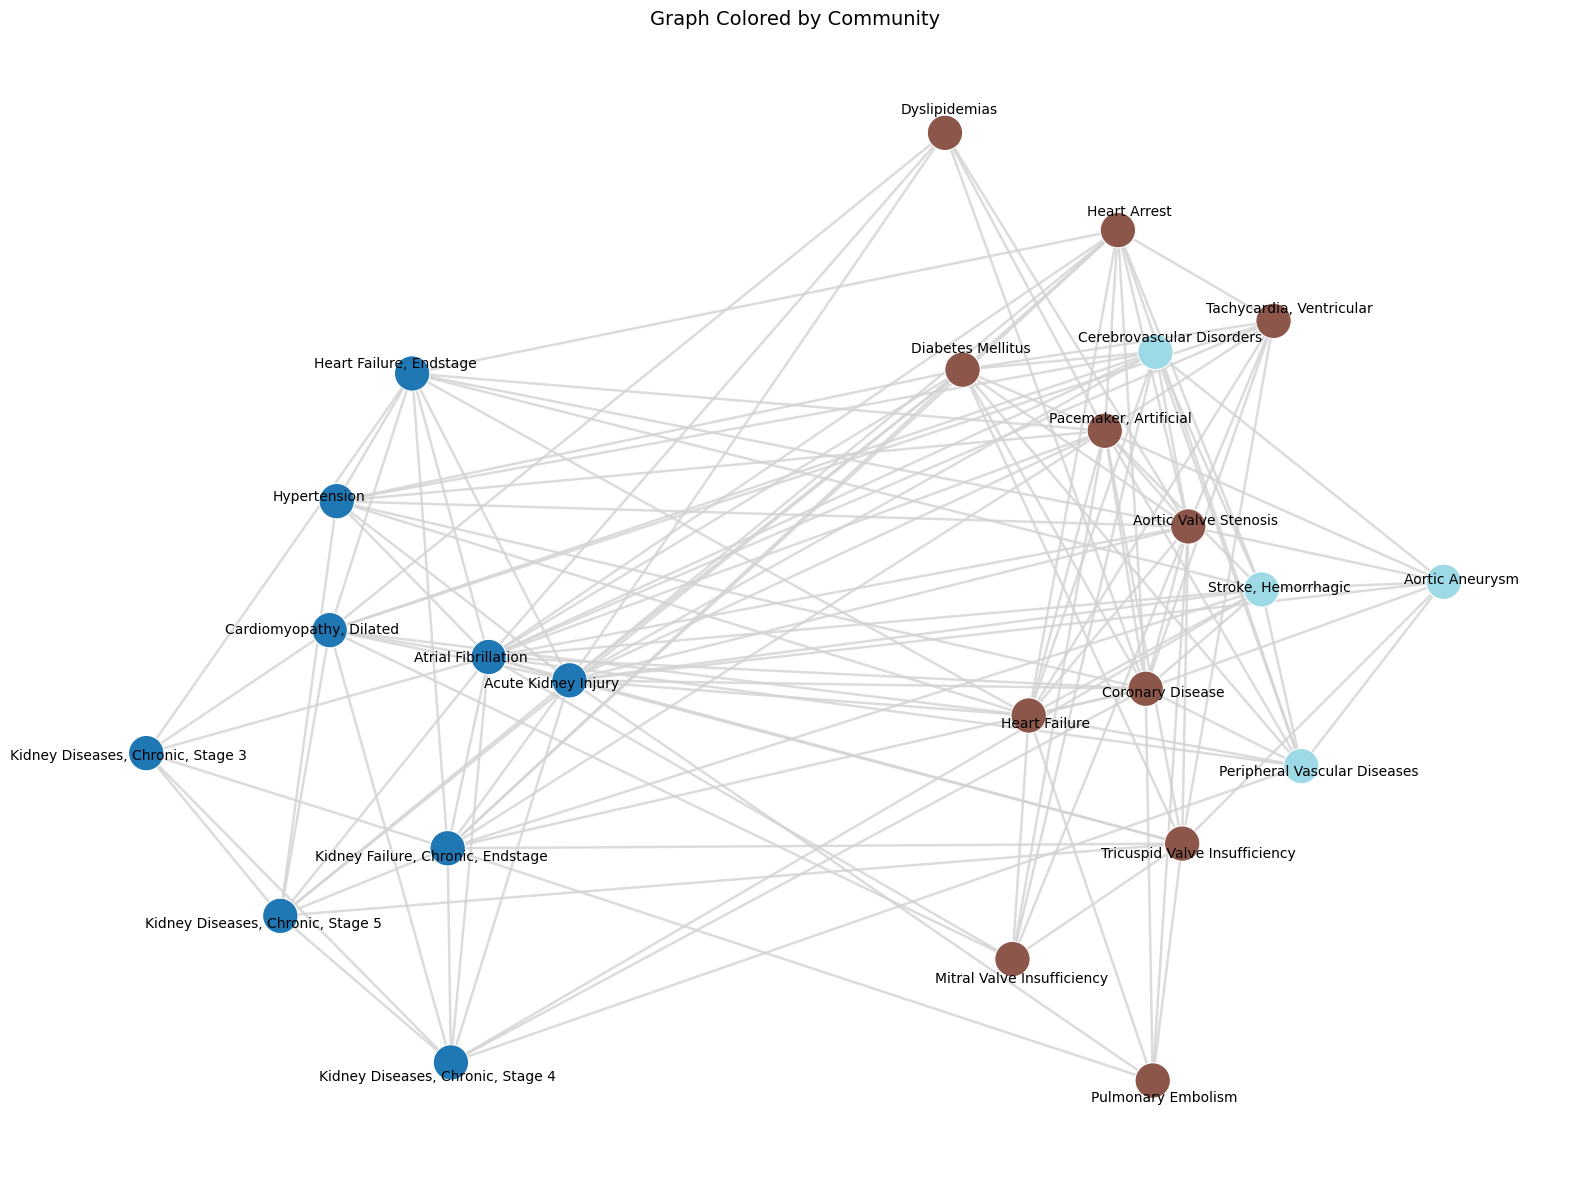

In [47]:
G = weighted_graph_construction(sign_df, threshold=0.0)

plot_graph_by_community(
    G, Community_detected,
    layout="nicely",
    separate_communities=True,
    separation_strength=0.5,   # try 2.0, 2.8, 3.5
    out="graph_GGM_plot_main_by_community.svg"
)